# Bab 13 — *Deploying* Model scikit-learn ke Produksi

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025), Bab 13
**Sumber kode:** [PacktPublishing/Scikit-Learn-Cookbook-Third-Edition](https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition) (`Chapter_13`)
**Direproduksi dan dijelaskan oleh:** Hadi Nugroho — NIM 101032330235 — S1 Teknik Komputer, Telkom University

**Resep yang dibahas**

| # | Resep | Alat utama |
|---|--------|-----------|
| 13.1 | Pengantar *Deployment* Model | `joblib.dump`, `joblib.load` |
| 13.2 | Teknik Serialisasi dan Persistensi | `pickle`, `joblib`, keamanan dan versi |
| 13.3 | *Scaling* Model untuk Produksi | `n_jobs`, latensi *batch*, `cross_val_score` paralel |
| 13.4 | Memantau dan Memperbarui Model yang Sudah Di-*deploy* | `SGDClassifier.partial_fit`, akurasi per *batch* |
| 13.5 | Mengelola Siklus Hidup Model | artefak berversi, metadata JSON, *snapshot* validasi |
| 13.6 | Menyiapkan *Pipeline Deployment* | `Pipeline`, gerbang validasi CI |
| 13.7 | Latihan Praktis *Deployment* Model | simpan/muat *pipeline*, pemantauan akurasi, pemeriksaan otomatis |

> Nomor resep ditambahkan di sini untuk memudahkan navigasi; buku aslinya tidak menomori resep. Resep 13.7 memakai solusi resmi dari notebook *Exercise Solutions* di repositori. (Pengantar notebook buku untuk bab ini menyebut "*cross-validation and model evaluation techniques*", sisa salin dari Bab 12; isinya adalah *deployment*.)

## Gambaran Umum Bab

Model yang hanya hidup di notebook belum memberi manfaat. ***Deployment*** memindahkan model dari lingkungan pengembangan ke lingkungan tempat sistem atau pengguna lain bisa meminta prediksi. Bab ini membahas siklus itu dari ujung ke ujung: **menyimpan** model terlatih sebagai artefak (*serialization*), **memuat dan menjalankannya** secara efisien (latensi, *throughput*, paralelisme), **memantau** kinerjanya setelah data dunia nyata mulai bergeser (*drift*), **memperbarui** model, **mencatat versi dan metadata** agar setiap model dapat ditelusuri, dan **mengotomatiskan** pemeriksaan sebelum model baru dipromosikan ke produksi (CI/CD/CT: *Continuous Integration / Delivery / Training*).

Hampir semua contoh memakai data sintetis kecil, jadi fokusnya pada **pola kerja** dan API, bukan akurasi. Beberapa contoh buku menyederhanakan skenario sampai angka evaluasinya tidak bermakna (data validasi acak, metadata versi yang ditulis tangan); sel tambahan menunjukkan di mana dan bagaimana memperbaikinya.

> **Catatan lingkungan.** Kode buku menulis beberapa file (`model.joblib`, `rf.pkl`, `rf_v1.0_metadata.json`, dll.) ke folder kerja. Agar repositori tetap bersih, sel persiapan di bawah memindahkan folder kerja notebook ini ke `artifacts_ch13/` (diabaikan Git lewat `.gitignore`). Kode buku sendiri tidak diubah.

## Persiapan

In [1]:
# Pustaka inti yang dipakai di sepanjang bab ini
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import os
from pathlib import Path
import joblib

# Satu seed global agar setiap eksekusi notebook menghasilkan angka yang sama.
# (Sel-sel buku tetap memakai nilai random_state masing-masing.)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Catat lingkungan persis yang menghasilkan output di bawah
print(f"Python       : {sys.version.split()[0]}")
print(f"numpy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")
print(f"joblib       : {joblib.__version__}")

Python       : 3.13.17
numpy        : 2.1.3
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.4
joblib       : 1.6.0


In [2]:
# Folder kerja khusus untuk file artefak yang ditulis kode buku (tambahan)
ART = Path.cwd() if Path.cwd().name == "artifacts_ch13" else (Path.cwd() / "artifacts_ch13")
ART.mkdir(exist_ok=True)
os.chdir(ART)
print("folder kerja:", Path.cwd().name)

folder kerja: artifacts_ch13


## Resep 13.1 — Pengantar *Deployment* Model

**Tujuan.** Melatih regresi logistik sederhana, menyimpannya ke disk dengan `joblib`, memuatnya kembali seolah di lingkungan baru, lalu membuat prediksi.

### Teori

**Intuisi.** Pelatihan biasanya dilakukan sekali (atau berkala), sedangkan prediksi dilakukan berkali-kali, sering di mesin lain. Karena itu model yang sudah dilatih harus disimpan sebagai **artefak**: sebuah file yang berisi semua parameter yang dipelajari (`coef_`, `intercept_`, `classes_`, dan sebagainya) beserta struktur objeknya. Artefak itu kemudian diunggah ke server dan dimuat oleh layanan prediksi.

**Matematika.** Regresi logistik yang disimpan sepenuhnya ditentukan oleh $\mathbf{w}\in\mathbb{R}^{20}$ dan $b$: $P(y=1\mid\mathbf{x})=\sigma(\mathbf{w}^\top\mathbf{x}+b)$. Menyimpan model berarti menyimpan angka-angka ini; model yang dimuat harus menghasilkan prediksi **identik bit demi bit** untuk input yang sama.

**Cara scikit-learn mengimplementasikannya.** scikit-learn tidak punya format penyimpanan sendiri; dokumentasinya merekomendasikan `joblib.dump(obj, path)` dan `joblib.load(path)`, yang memakai mekanisme *pickle* Python tetapi menangani array NumPy besar dengan efisien (opsional kompresi dan *memory mapping*).

**Asumsi, kelebihan, keterbatasan.**

* Paling mudah untuk lingkungan Python dengan versi pustaka yang sama.
* Model yang dimuat hanya bermakna untuk input dengan **distribusi fitur yang sama** seperti data latih. Contoh buku memprediksi `np.random.rand(1, 20)` (angka acak 0–1), yang tidak berasal dari distribusi data latih; prediksinya hanya menunjukkan bahwa API bekerja.

### Kode

In [3]:
# Muat pustaka
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from joblib import dump, load

# Buat dan latih model sederhana
X, y = make_classification(n_samples=1000, n_features=20, random_state=2024)
clf = LogisticRegression()
clf.fit(X, y)

LogisticRegression()

In [4]:
# Simpan model terlatih dengan joblib
dump(clf, "model.joblib")

# Muat kembali model
clf_loaded = load("model.joblib")

# Buat prediksi dengan model yang dimuat
incoming = np.random.rand(1, 20)
print(clf_loaded.predict(incoming))

[1]


In [5]:
# Apakah model yang dimuat identik dengan aslinya? (tambahan)
print(f"ukuran file model.joblib = {os.path.getsize('model.joblib'):,} byte")
print("coef_ identik:", np.array_equal(clf.coef_, clf_loaded.coef_), "| intercept_ identik:", np.array_equal(clf.intercept_, clf_loaded.intercept_))
print("prediksi pada 1.000 data latih identik:", np.array_equal(clf.predict(X), clf_loaded.predict(X)))
print("peluang kelas untuk input acak:", clf_loaded.predict_proba(incoming).round(3))
print(f"rentang fitur data latih: {X.min():.2f} s.d. {X.max():.2f}; input acak: {incoming.min():.2f} s.d. {incoming.max():.2f}")

ukuran file model.joblib = 1,023 byte
coef_ identik: True | intercept_ identik: True
prediksi pada 1.000 data latih identik: True
peluang kelas untuk input acak: [[0.099 0.901]]
rentang fitur data latih: -6.19 s.d. 4.82; input acak: 0.02 s.d. 0.97


**Interpretasi output.** Model yang dimuat memprediksi kelas **1** untuk input acak, dengan peluang 0,901. File `model.joblib` hanya berukuran ±1 KB, karena regresi logistik cukup menyimpan 20 koefisien, 1 intersep, dan atribut kecil lainnya. Sel tambahan memastikan `coef_`, `intercept_`, dan prediksi pada 1.000 data latih **identik** antara model asli dan model yang dimuat, sehingga serialisasi tidak mengubah apa pun. Namun input buku (`np.random.rand`) berada di rentang 0,02–0,97, sedangkan fitur data latih berada di rentang −6,19 sampai 4,82 dengan rata-rata sekitar nol. Input seperti itu tidak mewakili data yang pernah dilihat model; prediksinya hanya membuktikan bahwa jalur muat-lalu-prediksi berjalan.

### Poin Penting
* `joblib.dump`/`load` menyimpan dan memuat model terlatih; model yang dimuat identik dengan aslinya.
* Artefak regresi logistik sangat kecil (±1 KB).
* Input produksi harus berasal dari distribusi yang sama dengan data latih agar prediksi bermakna.

## Resep 13.2 — Teknik Serialisasi dan Persistensi

**Tujuan.** Menyimpan *random forest* dengan `pickle` dan `joblib`, memuat keduanya, dan memastikan prediksinya identik dengan model asli.

### Teori

**Intuisi.** *Serialization* mengubah objek di memori menjadi deretan byte yang dapat disimpan atau dikirim; *deserialization* membangunnya kembali. `pickle` adalah mekanisme bawaan Python; `joblib` membungkusnya dengan penanganan khusus untuk array NumPy (disimpan per blok, bisa dikompresi). Untuk lingkungan tanpa Python, model dapat dikonversi ke format netral seperti **ONNX** (lewat `skl2onnx`) atau PMML, walaupun tidak semua estimator didukung.

**Matematika.** *Random forest* yang disimpan berisi $B$ pohon, masing-masing dengan array `feature`, `threshold`, `children_left/right`, dan `value` per simpul. Ukuran artefak tumbuh kira-kira linear terhadap $B\times$ jumlah simpul, sehingga hutan besar bisa mencapai ratusan MB.

**Cara scikit-learn mengimplementasikannya.**

* `pickle.dump(obj, f)` / `pickle.load(f)` dengan file mode biner.
* `joblib.dump(obj, path, compress=0)` / `joblib.load(path, mmap_mode=None)`.
* Setiap estimator menyimpan `_sklearn_version` di *state*-nya; memuat artefak dengan versi scikit-learn lain memicu `InconsistentVersionWarning`, dan perilakunya tidak dijamin.

**Asumsi, kelebihan, keterbatasan.**

* **Keamanan:** memuat *pickle*/*joblib* dapat **mengeksekusi kode sembarang**. Jangan pernah memuat artefak dari sumber yang tidak dipercaya; format seperti `skops` atau ONNX lebih aman untuk dibagikan.
* **Kompatibilitas:** simpan versi Python, scikit-learn, dan NumPy bersama artefak (Resep 13.5).

### Kode

In [6]:
# Muat pustaka
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
import pickle
from joblib import dump, load

# Latih sebuah classifier
X, y = make_classification(n_samples=500, n_features=15, random_state=2024)
rf = RandomForestClassifier(n_estimators=10, random_state=2024)
rf.fit(X, y)

RandomForestClassifier(n_estimators=10, random_state=2024)

In [7]:
# Serialisasi dengan pickle
with open("rf.pkl", "wb") as f:
    pickle.dump(rf, f)

# Serialisasi dengan joblib
dump(rf, "rf.joblib")

# Muat model pickle
with open("rf.pkl", "rb") as f:
    rf1 = pickle.load(f)

# Muat model joblib
rf2 = load("rf.joblib")

# Pastikan perilaku identik setelah dimuat
assert np.array_equal(rf.predict(X[:5]), rf1.predict(X[:5]))
assert np.array_equal(rf.predict(X[:5]), rf2.predict(X[:5]))

In [8]:
# Ukuran artefak, versi yang tersimpan, dan kesetaraan pada seluruh data (tambahan)
for path in ["rf.pkl", "rf.joblib"]:
    print(f"{path:>9}: {os.path.getsize(path):,} byte")
dump(rf, "rf_compressed.joblib", compress=3)
print(f"rf_compressed.joblib (compress=3): {os.path.getsize('rf_compressed.joblib'):,} byte")
print("versi scikit-learn yang tercatat di artefak:", rf1.__getstate__().get("_sklearn_version"))
print("predict_proba identik pada 500 sampel:", np.array_equal(rf.predict_proba(X), rf1.predict_proba(X)), np.array_equal(rf.predict_proba(X), rf2.predict_proba(X)))
print("total simpul di 10 pohon:", sum(est.tree_.node_count for est in rf.estimators_))

   rf.pkl: 58,307 byte
rf.joblib: 59,225 byte
rf_compressed.joblib (compress=3): 13,587 byte
versi scikit-learn yang tercatat di artefak: 1.5.2
predict_proba identik pada 500 sampel: True True
total simpul di 10 pohon: 674


**Interpretasi output.** Kedua `assert` lolos tanpa pesan, artinya prediksi model hasil `pickle` dan `joblib` identik dengan model asli. Sel tambahan memperluas pemeriksaan ke `predict_proba` pada 500 sampel (juga identik). Ukuran artefak hampir sama: 58.307 byte (`pickle`) vs 59.225 byte (`joblib`). Keunggulan `joblib` baru terasa untuk array besar; dengan `compress=3`, file yang sama menyusut menjadi **13.587 byte** (±23 %). Isi utamanya adalah struktur 10 pohon dengan total 674 simpul. Artefak juga mencatat versi scikit-learn pembuatnya (**1.5.2**); memuatnya dengan versi lain akan memicu `InconsistentVersionWarning`.

### Poin Penting
* `pickle` dan `joblib` menghasilkan model yang identik; ukuran file mirip, dan `compress` memperkecil artefak ±4 kali.
* Artefak menyimpan `_sklearn_version`; versi pustaka saat memuat harus sama.
* Memuat *pickle* dapat mengeksekusi kode, jadi hanya muat artefak dari sumber tepercaya.

## Resep 13.3 — *Scaling* Model untuk Produksi

**Tujuan.** Mengukur waktu prediksi satu *batch* 1.000 sampel pada *random forest* 100 pohon dan menjalankan *cross-validation* paralel dengan `n_jobs=-1`.

### Teori

**Intuisi.** Di produksi ada dua ukuran kinerja yang berbeda: **latensi** (berapa lama satu permintaan dijawab) dan ***throughput*** (berapa banyak prediksi per detik). Memproses banyak input sekaligus (*batch*) hampir selalu jauh lebih efisien per sampel, karena biaya tetap setiap panggilan (validasi input, pemanggilan fungsi, alokasi memori) dibagi ke banyak sampel dan operasi NumPy tervektorisasi. Pelatihan dan evaluasi yang berat dapat dipercepat dengan paralelisme: banyak estimator scikit-learn menerima `n_jobs`, dan `joblib` dapat memakai *backend* terdistribusi seperti Dask.

**Matematika.** Jika satu panggilan `predict` berbiaya $t(n)\approx t_0+n\,t_1$ untuk $n$ sampel, maka waktu per sampel $t(n)/n=t_0/n+t_1$ turun mendekati $t_1$ saat $n$ besar. Untuk *random forest*, $t_1\propto B\times$ kedalaman pohon. Paralelisme ideal pada $p$ inti mempercepat pekerjaan yang dapat dibagi hingga $p$ kali, dikurangi biaya koordinasi (hukum Amdahl).

**Cara scikit-learn mengimplementasikannya.**

* `RandomForestClassifier(n_jobs=-1)`: pohon dilatih dan dipakai untuk prediksi secara paralel di semua inti.
* `cross_val_score(..., n_jobs=-1)`: fold dijalankan paralel.
* `joblib.parallel_backend('dask')` (dengan `dask.distributed`) mengirim pekerjaan ke klaster; buku hanya menyebutnya dalam komentar.

**Asumsi, kelebihan, keterbatasan.**

* Angka waktu bergantung pada mesin, beban CPU, dan jumlah inti, sehingga **berbeda setiap kali dijalankan**. Notebook ini dijalankan di lingkungan Linux 2 inti; angkanya hanya ilustrasi.
* Kode buku memakai `RandomForestClassifier(n_estimators=50)` **tanpa `random_state`** di `cross_val_score`, sehingga akurasi CV juga sedikit berubah setiap eksekusi.

### Kode

In [9]:
# Muat pustaka
import numpy as np
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import time

# Latih model forest pada data sintetis
X, y = make_classification(n_samples=2000, n_features=50, random_state=2024)
clf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=2024)
clf.fit(X, y)

RandomForestClassifier(n_jobs=-1, random_state=2024)

In [10]:
# Ukur latensi satu batch
batch = np.random.rand(1000, 50)
start = time.time()
clf.predict(batch)
print("Time:", time.time() - start)

# Latih dengan cross-validation paralel
scores = cross_val_score(RandomForestClassifier(n_estimators=50), X, y, cv=3, n_jobs=-1)
print("CV Accuracy:", np.mean(scores))

# (Opsional) Pakai Dask sebagai backend joblib jika tersedia
# from dask.distributed import Client
# from dask_ml.model_selection import GridSearchCV as daskGSCV

Time: 0.03464221954345703


CV Accuracy: 0.8719986853420135


In [11]:
# Latensi per sampel untuk berbagai ukuran batch, median 5 pengulangan (tambahan)
rows = []
for n in [1, 10, 100, 1000]:
    times = []
    for _ in range(5):
        t0 = time.perf_counter(); clf.predict(X[:n]); times.append(time.perf_counter() - t0)
    t = np.median(times)
    rows.append({"ukuran batch": n, "waktu panggilan (ms)": 1000 * t, "per sampel (ms)": 1000 * t / n, "prediksi/detik": n / t})
display(pd.DataFrame(rows).set_index("ukuran batch").round(3))
print("jumlah inti CPU terdeteksi:", os.cpu_count())
# Untuk satu permintaan, koordinasi thread (n_jobs=-1) bisa lebih mahal daripada pekerjaannya sendiri
for nj in [-1, 1]:
    clf.set_params(n_jobs=nj)
    t1 = np.median([(lambda t0: (clf.predict(X[:1]), time.perf_counter() - t0)[1])(time.perf_counter()) for _ in range(5)])
    print(f"n_jobs={nj:>2}: latensi 1 sampel = {1000 * t1:.2f} ms")
_ = clf.set_params(n_jobs=-1)

,waktu panggilan (ms),per sampel (ms),prediksi/detik
ukuran batch,,,
1,24.198,24.198,41.326
10,23.705,2.370,421.859
100,24.077,0.241,4153.330
1000,34.820,0.035,28719.233


jumlah inti CPU terdeteksi: 2
n_jobs=-1: latensi 1 sampel = 23.93 ms
n_jobs= 1: latensi 1 sampel = 3.23 ms


**Interpretasi output.**

* Sel buku mencatat sekitar **0,035 detik** untuk memprediksi 1.000 sampel dan akurasi CV sekitar **0,87–0,88**. Kedua angka sedikit berubah setiap eksekusi (waktu bergantung pada beban mesin; *forest* di dalam `cross_val_score` tidak punya `random_state`).
* Tabel tambahan memperlihatkan efek *batching* dengan jelas: satu panggilan `predict` memakan **puluhan milidetik** (±25–45 ms pada beberapa kali eksekusi) **hampir tanpa bergantung pada ukuran batch**. Akibatnya, waktu per sampel turun sekitar seribu kali, dari puluhan milidetik (batch 1) menjadi ±0,03–0,05 ms (batch 1.000), dan *throughput* naik dari puluhan menjadi puluhan ribu prediksi per detik. Hampir seluruh biaya adalah biaya tetap per panggilan.
* Biaya tetap itu sebagian besar berasal dari `n_jobs=-1` sendiri: menyiapkan *thread* untuk 100 pohon di setiap panggilan. Dengan `n_jobs=1`, latensi satu sampel turun menjadi **±3,3 ms**, sekitar 7–11 kali lebih cepat. Paralelisme membantu pekerjaan besar (pelatihan, *batch* besar), tetapi dapat **merugikan** layanan yang menjawab satu permintaan kecil setiap kali.

### Poin Penting
* Latensi dan *throughput* berbeda; *batching* menaikkan *throughput* ±1.000 kali karena biaya tetap per panggilan mendominasi.
* `n_jobs=-1` mempercepat pekerjaan besar tetapi menambah puluhan milidetik biaya koordinasi per panggilan kecil; untuk satu sampel, `n_jobs=1` ±7–11 kali lebih cepat.
* Angka waktu bergantung pada mesin dan berubah setiap eksekusi.

## Resep 13.4 — Memantau dan Memperbarui Model yang Sudah Di-*deploy*

**Tujuan.** Melatih `SGDClassifier` secara inkremental, memantau akurasinya pada empat *batch* data baru, dan memicu pembaruan (`partial_fit`) jika akurasi turun di bawah ambang 0,8.

### Teori

**Intuisi.** Setelah *deploy*, kinerja model hampir pasti menurun karena dunia berubah: ***data drift*** (distribusi fitur bergeser), ***concept drift*** (hubungan fitur–target berubah), atau ***label shift*** (proporsi kelas berubah). Karena itu siklus ML membutuhkan **CT (*Continuous Training*)** selain CI/CD: pantau metrik secara berkala, dan latih ulang atau perbarui model ketika metrik melewati ambang.

**Matematika.** `SGDClassifier(loss='log_loss')` adalah regresi logistik yang dioptimalkan dengan *stochastic gradient descent*: untuk setiap sampel, $\mathbf{w}\leftarrow\mathbf{w}-\eta_t\big(\nabla_{\mathbf{w}}\ell(y_i,\mathbf{w}^\top\mathbf{x}_i+b)+\alpha\mathbf{w}\big)$ dengan laju belajar $\eta_t$ yang menurun (jadwal `'optimal'`: $\eta_t=1/(\alpha(t_0+t))$). Karena pembaruan bersifat per sampel, model dapat **dilanjutkan** dengan data baru tanpa melatih ulang dari nol. Pemantauan sederhana: akurasi per *batch* $a_b$; picu pembaruan jika $\min_b a_b<\tau$.

**Cara scikit-learn mengimplementasikannya.**

* `partial_fit(X, y, classes=...)`: satu lintasan (*epoch*) SGD pada data yang diberikan; `classes` wajib pada panggilan pertama.
* `warm_start=True` hanya memengaruhi `fit` (memakai bobot sebelumnya sebagai titik awal); untuk `partial_fit` argumen ini tidak berpengaruh.
* Estimator lain yang mendukung pembelajaran inkremental: `MultinomialNB`, `Perceptron`, `PassiveAggressiveClassifier`, `MiniBatchKMeans`.

**Asumsi, kelebihan, keterbatasan.**

* Pemantauan akurasi butuh **label** data baru, yang sering datang terlambat; dalam praktik juga dipantau distribusi fitur dan prediksi (misalnya uji Kolmogorov–Smirnov atau PSI).
* Dalam kode buku, data "baru" dibangkitkan dengan `random_state=2025`, yaitu **masalah klasifikasi yang sepenuhnya berbeda** (bobot sebenarnya acak lagi), bukan pergeseran bertahap. Ini adalah *concept drift* ekstrem; sel tambahan memperlihatkan konsekuensinya.

### Kode

In [12]:
# Muat pustaka
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDClassifier
from sklearn.datasets import make_classification

# Simulasikan pelatihan awal dan data streaming
X_train, y_train = make_classification(n_samples=500, n_features=10, random_state=2024)
X_pub, y_pub = make_classification(n_samples=200, n_features=10, random_state=2025)
stream_batches = np.array_split(X_pub, 4)
stream_labels = np.array_split(y_pub, 4)

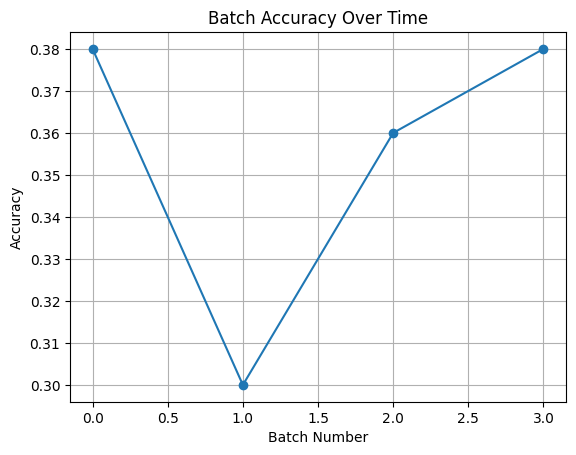

In [13]:
# Latih SGDClassifier inkremental pada data awal
clf = SGDClassifier(loss="log_loss", random_state=2024, warm_start=True)
clf.partial_fit(X_train, y_train, classes=np.unique(y_train))

# Pantau setiap batch yang masuk
batch_scores = []
for xb, yb in zip(stream_batches, stream_labels):
    yf = clf.predict(xb)
    batch_scores.append(np.mean(yf == yb))

# Picu pelatihan ulang jika akurasi turun di bawah ambang (misalnya < 0.8)
if min(batch_scores) < 0.8:
    clf.partial_fit(X_pub, y_pub)

# Gambar akurasi per batch
plt.plot(batch_scores, marker="o")
plt.title("Batch Accuracy Over Time")
plt.xlabel("Batch Number")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

In [14]:
# Akurasi per batch, efek pembaruan, dan bukti bahwa data baru adalah masalah lain (tambahan)
print("akurasi per batch sebelum pembaruan:", np.round(batch_scores, 3))
print(f"pembaruan dipicu? {min(batch_scores) < 0.8}")
sgd0 = SGDClassifier(loss="log_loss", random_state=2024).partial_fit(X_train, y_train, classes=np.unique(y_train))
print(f"model awal pada data latihnya sendiri : {sgd0.score(X_train, y_train):.3f}")
print(f"model awal pada seluruh X_pub         : {sgd0.score(X_pub, y_pub):.3f}")
print(f"setelah 1x partial_fit(X_pub): X_pub = {clf.score(X_pub, y_pub):.3f} (in-sample), data lama = {clf.score(X_train, y_train):.3f}")
fresh = SGDClassifier(loss="log_loss", random_state=2024).fit(X_pub[:100], y_pub[:100])
print(f"model baru dilatih pada 100 sampel X_pub, diuji pada 100 sisanya: {fresh.score(X_pub[100:], y_pub[100:]):.3f}")

akurasi per batch sebelum pembaruan: [0.38 0.3  0.36 0.38]
pembaruan dipicu? True
model awal pada data latihnya sendiri : 0.892
model awal pada seluruh X_pub         : 0.355
setelah 1x partial_fit(X_pub): X_pub = 0.865 (in-sample), data lama = 0.440
model baru dilatih pada 100 sampel X_pub, diuji pada 100 sisanya: 0.780


**Interpretasi output.**

* Akurasi pada keempat *batch* hanya **0,30–0,38**, di bawah tebakan acak (0,5). Grafik buku memperlihatkan "penurunan" ini sebagai alasan memicu pembaruan, dan pembaruan memang dipicu (min < 0,8).
* Sel tambahan menjelaskan penyebabnya. Model awal mencapai 0,892 pada data latihnya sendiri, tetapi hanya 0,355 pada `X_pub`. Akurasi di bawah 0,5 berarti hubungan fitur–label di `X_pub` hampir **berlawanan** dengan yang dipelajari: `make_classification(random_state=2025)` adalah masalah yang sepenuhnya baru, bukan data lama yang bergeser sedikit.
* Setelah satu kali `partial_fit` pada seluruh `X_pub`, akurasi pada `X_pub` naik menjadi 0,865 (diukur pada data yang sama dengan data pembaruan, jadi optimis), sementara akurasi pada data lama **jatuh ke 0,440**. Ini contoh ***catastrophic forgetting***: pembaruan inkremental menyesuaikan model dengan konsep baru dan menghapus konsep lama. Model baru yang dilatih hanya pada separuh `X_pub` mencapai 0,780 pada separuh lainnya.
* Pelajaran: pemantauan harus membedakan pergeseran bertahap (cukup diperbarui) dari perubahan konsep total (perlu dilatih ulang dan divalidasi ulang). Evaluasi setelah pembaruan juga harus memakai data yang belum dipakai untuk memperbarui.

### Poin Penting
* `partial_fit` memungkinkan pembaruan inkremental; `warm_start` tidak berpengaruh pada `partial_fit`.
* Data "baru" buku adalah masalah lain (akurasi 0,30–0,38, di bawah acak), bukan *drift* bertahap.
* Setelah pembaruan, akurasi data lama turun dari 0,892 ke 0,440 (*catastrophic forgetting*).

## Resep 13.5 — Mengelola Siklus Hidup Model

**Tujuan.** Menyimpan *random forest* sebagai artefak berversi (`rf_v1.0.joblib`) bersama file metadata lingkungan dan *snapshot* akurasi validasi.

### Teori

**Intuisi.** Setelah beberapa bulan, tim perlu bisa menjawab: model versi mana yang sedang berjalan, dilatih dengan kode dan data apa, di lingkungan pustaka versi berapa, dan seberapa baik kinerjanya waktu itu? Tanpa catatan ini, masalah di produksi sulit ditelusuri dan *rollback* ke versi sebelumnya berisiko. Praktik yang dianjurkan (termasuk oleh dokumentasi scikit-learn) adalah menyimpan, bersama setiap artefak, **versi pustaka**, **kode/konfigurasi pelatihan**, dan **set validasi kecil beserta prediksi atau skornya**, sehingga model dapat diperiksa ulang setelah pustaka diperbarui.

**Matematika.** *Snapshot* validasi menyimpan $\hat a_{\text{val}}=\frac1{|V|}\sum_{i\in V}\mathbb{1}[\hat y_i=y_i]$ untuk set validasi $V$. Agar bermakna, $V$ harus **terpisah** dari data latih; jika $V\subset D_{\text{latih}}$, $\hat a_{\text{val}}$ mengukur kemampuan menghafal, bukan generalisasi (untuk *random forest* biasanya ≈ 1).

**Cara scikit-learn mengimplementasikannya.** Tidak ada API khusus; buku memakai `joblib.dump` dengan nama file berversi, `json.dump` untuk metadata, dan file teks untuk skor. Alat seperti MLflow, DVC, atau *model registry* di platform cloud mengotomatiskan pola yang sama.

**Asumsi, kelebihan, keterbatasan.** Di kode buku ada dua hal yang perlu diperhatikan (dibahas di bawah output): metadata versi scikit-learn **ditulis tangan** (`"1.3.2"`) alih-alih dibaca dari lingkungan, dan "set validasi" `Xv` diambil dari data yang **sama** dengan data latih model.

### Kode

In [15]:
# Muat pustaka
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
from joblib import dump
import json

# Latih model dan simulasikan lingkungan berversi
X, y = make_classification(n_samples=800, n_features=20, random_state=2024)
clf = RandomForestClassifier(n_estimators=50, random_state=2024)
clf.fit(X, y)

RandomForestClassifier(n_estimators=50, random_state=2024)

In [16]:
from sklearn.model_selection import train_test_split

# Pakai X dan y dari sel 17 (sudah didefinisikan dan dipakai untuk melatih clf)
Xv, _, yv, _ = train_test_split(X, y, test_size=0.8, random_state=2024)

# Simpan artefak model dengan nama file berversi
version = "v1.0"
dump(clf, f"rf_{version}.joblib")

# Simpan metadata lingkungan pelatihan
meta = {"version": version, "sklearn": "1.3.2", "numpy": str(np.__version__)}
with open(f"rf_{version}_metadata.json", "w") as f:
    json.dump(meta, f)

# Rekam snapshot kinerja pada set validasi
yv_pred = clf.predict(Xv)
val_acc = accuracy_score(yv, yv_pred)
with open(f"rf_{version}_val.txt", "w") as f:
    f.write(f"{val_acc:.4f}")

In [17]:
# Isi file yang dihasilkan dan dua masalahnya (tambahan)
import sklearn
print("metadata tersimpan :", json.load(open(f"rf_{version}_metadata.json")))
print("versi sebenarnya    :", {"sklearn": sklearn.__version__, "numpy": np.__version__})
print("snapshot validasi   :", open(f"rf_{version}_val.txt").read(), f"pada {len(Xv)} sampel")
train_rows = {tuple(r) for r in X}
print(f"sampel Xv yang juga ada di data latih clf: {sum(tuple(r) in train_rows for r in Xv)} dari {len(Xv)}")

# Versi yang lebih jujur: holdout sungguhan dan metadata dibaca dari lingkungan
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=2024)
clf_h = RandomForestClassifier(n_estimators=50, random_state=2024).fit(X_tr, y_tr)
meta_ok = {"version": version, "sklearn": sklearn.__version__, "numpy": np.__version__,
           "python": sys.version.split()[0], "n_train": len(X_tr), "val_accuracy_holdout": round(accuracy_score(y_val, clf_h.predict(X_val)), 4)}
print("metadata yang disarankan:", meta_ok)

metadata tersimpan : {'version': 'v1.0', 'sklearn': '1.3.2', 'numpy': '2.1.3'}
versi sebenarnya    : {'sklearn': '1.5.2', 'numpy': '2.1.3'}
snapshot validasi   : 1.0000 pada 160 sampel
sampel Xv yang juga ada di data latih clf: 160 dari 160
metadata yang disarankan: {'version': 'v1.0', 'sklearn': '1.5.2', 'numpy': '2.1.3', 'python': '3.13.17', 'n_train': 640, 'val_accuracy_holdout': 0.9563}


**Interpretasi output.** Kode buku menghasilkan tiga file (artefak `rf_v1.0.joblib` ±410 KB, metadata, dan skor validasi) tanpa output tercetak. Sel tambahan membaca isinya dan menemukan dua masalah:

* **Metadata tidak jujur.** File mencatat `"sklearn": "1.3.2"`, padahal model dilatih dengan scikit-learn **1.5.2**. Versi ditulis tangan di kode, sehingga metadata akan salah setiap kali lingkungan berubah, padahal tujuan metadata justru mendeteksi perubahan itu. Versi NumPy benar karena dibaca dari `np.__version__`.
* ***Snapshot* validasi tidak memvalidasi apa pun.** `Xv` (160 sampel) diambil dari `X` yang sama yang dipakai untuk melatih `clf`; semua **160 dari 160** sampel ada di data latih. Akurasi **1,0000** hanya menunjukkan *random forest* menghafal data latihnya.

Versi yang disarankan (sel yang sama) melatih model pada 80 % data, mengukur akurasi pada 20 % *holdout* yang tidak pernah dilihat (**0,956**), dan mengisi metadata dari lingkungan yang sebenarnya, termasuk versi Python dan jumlah sampel latih.

### Poin Penting
* Simpan artefak berversi bersama metadata lingkungan dan *snapshot* validasi.
* Baca versi pustaka dari lingkungan (`sklearn.__version__`), jangan ditulis tangan ("1.3.2" vs 1.5.2 yang sebenarnya).
* *Snapshot* validasi harus memakai data yang tidak dipakai untuk melatih (1,000 in-sample vs 0,956 *holdout*).

## Resep 13.6 — Menyiapkan *Pipeline Deployment*

**Tujuan.** Membungkus standardisasi dan regresi logistik dalam satu `Pipeline`, menyimpannya sebagai satu artefak, lalu mensimulasikan gerbang CI: *deploy* hanya jika akurasi validasi > 0,8.

### Teori

**Intuisi.** Jika pra-pemrosesan (misalnya `StandardScaler`) disimpan terpisah dari model, mudah sekali terjadi ketidakcocokan antara pelatihan dan produksi (*training–serving skew*): skala dihitung ulang dengan data lain, atau langkahnya terlupa. `Pipeline` menggabungkan seluruh logika inferensi ke **satu objek**, sehingga artefak yang diuji sama persis dengan artefak yang dijalankan. Di sistem CI/CD, artefak baru kemudian melewati **gerbang validasi**: ia hanya dipromosikan jika lolos ambang kinerja pada set validasi atau *canary* yang representatif.

**Matematika.** `Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())])` mengimplementasikan $f(\mathbf{x})=\sigma\big(\mathbf{w}^\top\frac{\mathbf{x}-\boldsymbol\mu}{\boldsymbol s}+b\big)$, dengan $\boldsymbol\mu,\boldsymbol s$ dipelajari saat `fit` dan dibekukan di dalam artefak. Gerbang: *deploy* $\iff\hat a_{\text{val}}>\tau$, dengan $\tau=0{,}8$.

**Cara scikit-learn mengimplementasikannya.** `Pipeline.fit` memanggil `fit_transform` setiap langkah lalu `fit` langkah terakhir; `Pipeline.predict` memanggil `transform` lalu `predict`. Seluruh objek dapat disimpan dengan `joblib.dump`.

**Asumsi, kelebihan, keterbatasan.** Gerbang validasi hanya sebaik set validasinya. Kode buku memakai `Xt = np.random.rand(100, 10)` dan **label acak** `np.random.randint(0, 2, 100)`: data yang tidak berhubungan dengan masalah yang dipelajari model. Akurasi yang dihasilkan karena itu sekitar 0,5 berapa pun kualitas modelnya, sehingga gerbang akan selalu menolak (atau, dengan keberuntungan, meloloskan) model secara acak. Sel tambahan menunjukkan gerbang yang memakai data validasi sungguhan.

### Kode

In [18]:
# Muat pustaka
import numpy as np
from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from joblib import dump, load
from sklearn.metrics import accuracy_score

# Buat data dan pipeline
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression())
])
pipe.fit(X, y)

Pipeline(steps=[('scale', StandardScaler()), ('clf', LogisticRegression())])

In [19]:
# Ekspor seluruh pipeline
dump(pipe, "pipeline.joblib")

#Muat pipeline di lingkungan deployment
prod_pipe = load("pipeline.joblib")

# Simulasikan CI: validasi akurasi pada set uji
Xt, yt = np.random.rand(100, 10), np.random.randint(0, 2, 100)
acc = accuracy_score(yt, prod_pipe.predict(Xt))
print("Validation accuracy:", acc)

# Deploy secara bersyarat hanya jika akurasi > ambang (misalnya > 0.8)
if acc > 0.8:
    print("Auto-deploy allowed")
else:
    print("Halt deployment and review")

Validation accuracy: 0.55
Halt deployment and review


In [20]:
# Gerbang validasi dengan data yang representatif (tambahan)
from sklearn.model_selection import train_test_split
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=2024, stratify=y)
candidate = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())]).fit(X_tr, y_tr)
dump(candidate, "pipeline_candidate.joblib")
acc_ok = accuracy_score(y_val, load("pipeline_candidate.joblib").predict(X_val))
print(f"akurasi pada {len(y_val)} sampel validasi sungguhan: {acc_ok:.3f} ->", "Auto-deploy allowed" if acc_ok > 0.8 else "Halt deployment and review")
print("statistik scaler yang dibekukan di artefak (5 fitur pertama):", load("pipeline_candidate.joblib").named_steps["scale"].mean_[:5].round(3))
print(f"proporsi label acak = 1 di sel buku: {yt.mean():.2f}; proporsi prediksi = 1: {prod_pipe.predict(Xt).mean():.2f}")

akurasi pada 100 sampel validasi sungguhan: 0.880 -> Auto-deploy allowed
statistik scaler yang dibekukan di artefak (5 fitur pertama): [ 0.058 -0.012 -0.028  0.054  0.073]
proporsi label acak = 1 di sel buku: 0.48; proporsi prediksi = 1: 0.67


**Interpretasi output.** Gerbang CI buku menghasilkan akurasi **0,55** dan menghentikan *deployment* ("*Halt deployment and review*"). Angka ini tidak mengatakan apa pun tentang kualitas model: data validasinya adalah angka acak 0–1 dengan label acak (48 % kelas 1), sehingga akurasi mana pun di sekitar 0,5 hanya kebetulan. Model memprediksi kelas 1 untuk 67 % input acak itu, karena semua nilai inputnya positif dan berada di luar distribusi data latih.

Gerbang yang sama dengan data validasi sungguhan (20 % *holdout* dari distribusi yang sama, model dilatih pada 80 % sisanya) memberi akurasi **0,880** dan meloloskan model. *Pipeline* yang dimuat juga membawa statistik `StandardScaler` yang dibekukan saat pelatihan, sehingga produksi memakai skala yang persis sama.

### Poin Penting
* `Pipeline` menyatukan pra-pemrosesan dan model dalam satu artefak, mencegah *training–serving skew*.
* Gerbang validasi buku memakai data dan label acak (akurasi 0,55, *deployment* ditolak secara acak).
* Dengan *holdout* yang representatif, gerbang yang sama memberi 0,880 dan meloloskan model.

## Resep 13.7 — Latihan Praktis *Deployment* Model

**Tujuan.** Mengerjakan tiga latihan buku: (1) menyimpan dan memuat ulang *pipeline*, (2) memantau akurasi per *batch* model SGD dengan regularisasi sangat kuat, (3) pemeriksaan otomatis sebelum *deployment* dengan ambang akurasi.

### Teori

* **Latihan 1:** pola Resep 13.6 dengan nama langkah berbeda (`scaler`, `model`); keluarannya adalah prediksi 5 sampel pertama dari *pipeline* yang dimuat ulang.
* **Latihan 2:** memakai ulang `X_train` dan *batch* dari Resep 13.4, tetapi dengan `loss="hinge"` (SVM linear) dan `alpha=1.0`, yaitu regularisasi 10.000 kali lebih kuat daripada default (0,0001). Tujuannya membuat model sengaja kurang akurat agar penurunan terlihat di grafik pemantauan.
* **Latihan 3:** model dilatih pada `make_classification(random_state=2024)` lalu diuji pada `make_classification(random_state=2025)`. Seperti di Resep 13.4, kedua set ini adalah **masalah yang berbeda**, sehingga gerbang ini pada dasarnya menguji model pada tugas lain.

### Kode

### Kode — Latihan 1: Menyimpan dan Memuat Ulang *Pipeline* Model untuk *Deployment*

In [21]:
# Muat pustaka
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from joblib import dump, load

# Buat dan latih pipeline
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression())
])
pipe.fit(X, y)

# Simpan dan muat ulang pipeline
dump(pipe, "model_pipeline.joblib")
loaded_pipe = load("model_pipeline.joblib")

# Buat prediksi baru
print(loaded_pipe.predict(X[:5]))

[1 1 1 0 0]


In [22]:
# Kesetaraan pipeline asli dan yang dimuat (tambahan)
print("label sebenarnya 5 sampel pertama:", y[:5])
print("prediksi identik pada 500 sampel:", np.array_equal(pipe.predict(X), loaded_pipe.predict(X)), "| akurasi latih:", round(loaded_pipe.score(X, y), 3))

label sebenarnya 5 sampel pertama: [1 1 0 0 0]
prediksi identik pada 500 sampel: True | akurasi latih: 0.908


**Interpretasi output.** *Pipeline* yang dimuat memprediksi `[1 1 1 0 0]` untuk lima sampel pertama, sedangkan label sebenarnya `[1 1 0 0 0]`: satu dari lima salah. Sel tambahan memastikan prediksi *pipeline* asli dan yang dimuat identik pada seluruh 500 sampel, dengan akurasi latih 0,908. Latihan ini mengulang pola Resep 13.6: satu artefak berisi scaler dan model, dimuat dan langsung dipakai.

### Kode — Latihan 2: Memantau Akurasi Model dari Waktu ke Waktu

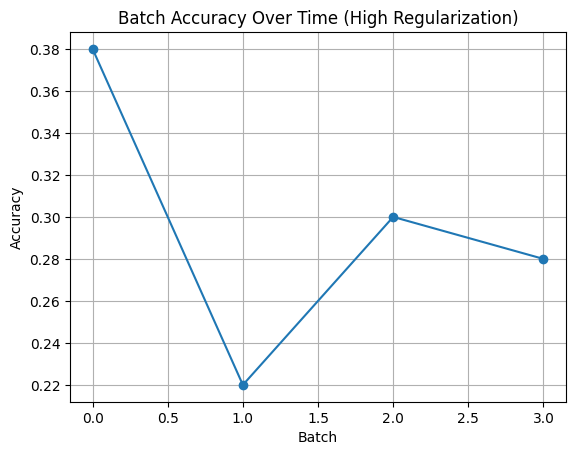

In [23]:
# Ubah hiperparameter SGDClassifier agar model kurang akurat
clf = SGDClassifier(loss="hinge", alpha=1.0, random_state=2024)  # Pakai loss SVM dan regularisasi kuat
clf.partial_fit(X_train, y_train, classes=np.unique(y_train))
batch_scores = []
for Xb, yb in zip(stream_batches, stream_labels):
    acc = np.mean(clf.predict(Xb) == yb)
    batch_scores.append(acc)

# Gambar akurasi per batch
plt.plot(batch_scores, marker='o')
plt.xlabel("Batch")
plt.ylabel("Accuracy")
plt.title("Batch Accuracy Over Time (High Regularization)")
plt.grid(True)
plt.show()

In [24]:
# Akurasi per batch dan perbandingan dengan model Resep 13.4 (tambahan)
print("akurasi per batch (alpha=1.0, hinge):", np.round(batch_scores, 3))
print(f"akurasi pada data latihnya sendiri: {clf.score(X_train, y_train):.3f} | norma bobot = {np.linalg.norm(clf.coef_):.4f}")
print(f"pembanding (log_loss, alpha default) pada data latih: {sgd0.score(X_train, y_train):.3f} | norma bobot = {np.linalg.norm(sgd0.coef_):.4f}")
cos = float(clf.coef_.ravel() @ sgd0.coef_.ravel() / (np.linalg.norm(clf.coef_) * np.linalg.norm(sgd0.coef_)))
print(f"cosine similarity arah bobot kedua model = {cos:.3f}")

akurasi per batch (alpha=1.0, hinge): [0.38 0.22 0.3  0.28]
akurasi pada data latihnya sendiri: 0.902 | norma bobot = 0.5604
pembanding (log_loss, alpha default) pada data latih: 0.892 | norma bobot = 77.9378
cosine similarity arah bobot kedua model = 0.932


**Interpretasi output.** Model SGD dengan *hinge loss* dan `alpha=1.0` mendapat akurasi **0,22–0,38** per *batch*, sedikit lebih rendah daripada model Resep 13.4 (0,30–0,38), sehingga grafik "penurunan" memang terlihat. Namun sel tambahan memperlihatkan bahwa regularisasi kuat **bukan** penyebab utamanya: pada data latihnya sendiri model ini justru mencapai 0,902 (vs 0,892 untuk model Resep 13.4). Regularisasi memperkecil norma bobot dari 77,9 menjadi 0,56, tetapi arah bobot, yang menentukan prediksi, tetap mirip (*cosine similarity* 0,93). Akurasi rendah pada *batch* berasal dari masalah yang sama seperti di Resep 13.4: `X_pub` adalah tugas klasifikasi yang berbeda. Latihan ini lebih tepat dibaca sebagai demonstrasi cara memantau dan menggambar akurasi per *batch*.

### Kode — Latihan 3: Mengotomatiskan Pemeriksaan *Deployment* dengan Ambang Validasi

In [25]:
# Muat pustaka
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from joblib import dump, load
from sklearn.metrics import accuracy_score

# Latih dan ekspor model
X, y = make_classification(n_samples=300, n_features=10, random_state=2024)
model = LogisticRegression()
model.fit(X, y)
dump(model, "model_ci.joblib")

# Muat dan validasi dengan data uji
Xt, yt = make_classification(n_samples=100, n_features=10, random_state=2025)
model_prod = load("model_ci.joblib")
pred = model_prod.predict(Xt)
acc = accuracy_score(yt, pred)
print(f"Test Accuracy: {acc:.3f}")

# Setujui deployment secara bersyarat
if acc > 0.8:
    print("Deployment approved")
else:
    print("Deployment rejected")

Test Accuracy: 0.110
Deployment rejected


In [26]:
# Gerbang yang sama dengan data uji dari distribusi yang sama (tambahan)
X_all, y_all = make_classification(n_samples=400, n_features=10, random_state=2024)
m = LogisticRegression().fit(X_all[:300], y_all[:300])
acc_same = accuracy_score(y_all[300:], m.predict(X_all[300:]))
print(f"akurasi pada 100 sampel uji dari distribusi yang sama: {acc_same:.3f} ->", "Deployment approved" if acc_same > 0.8 else "Deployment rejected")

akurasi pada 100 sampel uji dari distribusi yang sama: 0.850 -> Deployment approved


**Interpretasi output.** Akurasi uji hanya **0,110** dan *deployment* ditolak. Akurasi jauh di bawah 0,5 berarti model hampir selalu menebak **kebalikan** label: data uji `random_state=2025` adalah masalah lain yang kebetulan hampir berlawanan dengan masalah latih. Gerbang ini menolak model dengan alasan yang salah. Dengan 100 sampel uji dari distribusi yang **sama** (sel tambahan), model regresi logistik yang sama mencapai **0,850** dan disetujui. Gerbang otomatis berguna hanya jika data validasinya mewakili data produksi yang diharapkan.

### Poin Penting
* *Pipeline* yang disimpan dan dimuat ulang memberi prediksi identik (akurasi latih 0,908).
* Regularisasi sangat kuat (`alpha=1.0`) memperkecil bobot tetapi tidak menurunkan akurasi latih (0,902); akurasi *batch* rendah karena datanya masalah lain.
* Gerbang CI pada data dari distribusi lain: 0,110 (ditolak); pada distribusi yang sama: 0,850 (disetujui).

In [27]:
# File artefak yang dihasilkan notebook ini (tambahan)
for p in sorted(Path.cwd().iterdir()):
    print(f"{p.name:<28} {p.stat().st_size:>9,} byte")

model.joblib                     1,023 byte
model_ci.joblib                    943 byte
model_pipeline.joblib            1,646 byte
pipeline.joblib                  1,646 byte
pipeline_candidate.joblib        1,646 byte
rf.joblib                       59,225 byte
rf.pkl                          58,307 byte
rf_compressed.joblib            13,587 byte
rf_v1.0.joblib                 409,785 byte
rf_v1.0_metadata.json               57 byte
rf_v1.0_val.txt                      6 byte


## Ringkasan Bab

| Resep | Konsep | Kelas/fungsi sklearn utama | Poin penting |
|---|---|---|---|
| 13.1 Pengantar *Deployment* | Artefak model, simpan–muat | `joblib.dump`, `joblib.load` | Model yang dimuat identik; artefak regresi logistik ±1 KB. Input acak buku di luar distribusi data latih. |
| 13.2 Serialisasi | `pickle` vs `joblib`, keamanan, versi | `pickle`, `joblib` | Ukuran mirip (±58 KB), `compress=3` → 13,6 KB; artefak mencatat versi 1.5.2. |
| 13.3 *Scaling* | Latensi vs *throughput*, `n_jobs` | `n_jobs`, `cross_val_score(n_jobs=-1)` | Biaya tetap puluhan ms per panggilan; `n_jobs=1` ±7–11× lebih cepat untuk 1 sampel. |
| 13.4 Pemantauan | *Drift*, CT, pembaruan inkremental | `SGDClassifier.partial_fit` | Data "baru" adalah masalah lain (0,30–0,38); pembaruan menjatuhkan akurasi data lama ke 0,440. |
| 13.5 Siklus Hidup | Artefak berversi, metadata, *snapshot* | `joblib`, `json` | Versi ditulis tangan ("1.3.2" vs 1.5.2); validasi in-sample 1,000 vs *holdout* 0,956. |
| 13.6 *Pipeline Deployment* | Satu artefak, gerbang CI | `Pipeline` | Gerbang buku memakai data acak (0,55); dengan *holdout* sungguhan 0,880. |
| 13.7 Latihan Praktis | Simpan/muat *pipeline*, pemantauan, gerbang otomatis | `Pipeline`, `SGDClassifier`, `LogisticRegression` | Gerbang pada distribusi lain 0,110 (ditolak) vs distribusi sama 0,850 (disetujui). |

**Penutup.** Bab terakhir ini menghubungkan seluruh isi buku ke praktik nyata: model dari Bab 2–11 dievaluasi dengan teknik Bab 12, lalu disimpan, dijalankan, dipantau, dan diperbarui. Pelajaran utamanya bukan API `joblib`, melainkan disiplin di sekitarnya: artefak harus bisa ditelusuri, metadata harus dibaca dari lingkungan, dan setiap angka validasi harus berasal dari data yang representatif dan belum pernah dilihat model. Beberapa contoh buku melanggar prinsip-prinsip ini, dan menemukannya adalah latihan yang baik untuk proyek sendiri.

## Referensi

* Sukup, J. (2025). *scikit-learn Cookbook, Third Edition*. Packt Publishing. Bab 13.
* Repositori kode resmi: <https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition>
* scikit-learn User Guide — Model persistence: <https://scikit-learn.org/1.5/model_persistence.html>
* scikit-learn User Guide — Strategies to scale computationally: bigger data (incremental learning): <https://scikit-learn.org/1.5/computing/scaling_strategies.html>
* scikit-learn User Guide — Parallelism, resource management, and configuration: <https://scikit-learn.org/1.5/computing/parallelism.html>
* joblib documentation — Persistence: <https://joblib.readthedocs.io/en/stable/persistence.html>
* Sculley, D., dkk. (2015). Hidden technical debt in machine learning systems. *Advances in Neural Information Processing Systems*, 28.
* Gama, J., Žliobaitė, I., Bifet, A., Pechenizkiy, M., & Bouchachia, A. (2014). A survey on concept drift adaptation. *ACM Computing Surveys*, 46(4), 44.